<a href="https://colab.research.google.com/github/yeondajang/Computer-vision/blob/main/HW_Linear_Classification(2023112684_%EC%9E%A5%EB%8B%A4%EC%97%B0).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##1. Preprocessing

In [41]:
!ls -l /content/cifar-10-python.tar.gz

-rw-r--r-- 1 root root 170498071 Nov 18 04:55 /content/cifar-10-python.tar.gz


In [42]:
!rm -rf /content/cifar-10-batches-py
TAR_PATH = '/content/cifar-10-python.tar.gz'
DATA_DIR = '/content/cifar-10-batches-py'
if not os.path.exists(os.path.join(DATA_DIR, 'test_batch')):
    with tarfile.open(TAR_PATH, 'r:gz') as tar:
        tar.extractall('/content')

/tmp/ipykernel_2805/2946463258.py:6: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall('/content')


In [43]:
import os
import pickle
import tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', lambda v: f'{v:.4f}')
pd.set_option('display.width', 200)

TAR_PATH = '/content/cifar-10-python.tar.gz'
DATA_DIR = 'cifar-10-batches-py'
if not os.path.isdir(DATA_DIR):
    with tarfile.open(TAR_PATH, 'r:gz') as tar:
        tar.extractall('.')

def load_batch(path):
    with open(path, 'rb') as f:
        d = pickle.load(f, encoding='bytes')
    imgs = d[b'data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)   # 채널 우선 -> HWC
    return imgs, np.array(d[b'labels'])

with open(os.path.join(DATA_DIR, 'batches.meta'), 'rb') as f:
    CLASSES = [c.decode() for c in pickle.load(f, encoding='bytes')[b'label_names']]

train_imgs = np.concatenate([load_batch(os.path.join(DATA_DIR, f'data_batch_{i}'))[0] for i in range(1, 6)])
X_img, y = load_batch(os.path.join(DATA_DIR, 'test_batch'))

print('클래스:', CLASSES)
print('학습 이미지:', train_imgs.shape, '| 테스트 이미지:', X_img.shape, '| 테스트 레이블:', y.shape)
print('테스트 클래스별 개수:', np.bincount(y))

클래스: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
학습 이미지: (50000, 32, 32, 3) | 테스트 이미지: (10000, 32, 32, 3) | 테스트 레이블: (10000,)
테스트 클래스별 개수: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


각 이미지를 3072차원(32×32×3) 벡터로 펼치고, 픽셀 값을 0~1로 바꾼 뒤 학습 세트의 평균 이미지를 빼서 0 근처에 모이도록 함. 수업에서처럼 `x`는 열벡터(3072×1)로 보고, 여러 장을 한 번에 계산할 때는 열 방향으로 쌓은 `X`(3072×N)를 씀.

In [44]:
mean_image = (train_imgs.reshape(len(train_imgs), -1).astype(np.float64) / 255.0).mean(axis=0)
X_flat = X_img.reshape(len(X_img), -1).astype(np.float64) / 255.0
del train_imgs
X = (X_flat - mean_image).T
D, N = X.shape
K = len(CLASSES)
print(f'D = {D}, N = {N}, K = {K}')

D = 3072, N = 10000, K = 10


##2. weight `w` bias `b`

In [45]:
SEED = 42
rng = np.random.default_rng(SEED)

W = 0.01 * rng.standard_normal((K, D))
b = np.zeros((K, 1))

print('W shape:', W.shape, '| 평균 %.5f, 표준편차 %.5f' % (W.mean(), W.std()))
print('b shape:', b.shape, '| 모든 값이 0:', np.all(b == 0))

W shape: (10, 3072) | 평균 0.00009, 표준편차 0.01004
b shape: (10, 1) | 모든 값이 0: True


`W`는 평균 0, 표준편차 0.01인 정규분포에서 뽑았고 `b`는 모두 0. 시드는 42로 고정.

##3. `f(x) = Wx + b`

In [46]:
def linear_classifier(X, W, b):
    """X: (D, N) 열벡터들, W: (K, D), b: (K, 1) -> 점수 (K, N)"""
    return W @ X + b

example_idx = np.array([rng.choice(np.where(y == c)[0]) for c in range(K)])
X_ex, y_ex = X[:, example_idx], y[example_idx]

scores = linear_classifier(X_ex, W, b)
pred_ex = scores.argmax(axis=0)

score_df = pd.DataFrame(scores.T, columns=CLASSES,
                        index=[f'#{i} ({CLASSES[t]})' for i, t in zip(example_idx, y_ex)])
score_df['예측'] = [CLASSES[p] for p in pred_ex]
score_df['정답'] = [CLASSES[t] for t in y_ex]
score_df

,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck,예측,정답
#257 (airplane),-0.5145,-0.2927,-0.2054,-0.1615,0.1277,0.2145,0.6585,0.1085,0.0504,-0.1412,frog,airplane
#5422 (automobile),-0.2474,-0.3282,0.0014,0.0839,0.0115,0.1349,0.0994,-0.0234,0.2012,0.0001,ship,automobile
#9603 (bird),0.1134,0.1964,0.0229,-0.0783,-0.0539,-0.1546,-0.0432,-0.1735,-0.1679,0.0125,automobile,bird
#53 (cat),-0.0899,-0.0169,0.2219,0.1693,-0.0194,-0.0516,0.0159,-0.0130,0.0497,-0.1172,bird,cat
#8153 (deer),-0.1589,-0.0152,-0.0549,-0.1916,0.0042,0.2765,0.3231,0.1346,0.2034,0.0466,frog,deer
#9939 (dog),0.1207,-0.2253,-0.0943,0.2664,0.0605,-0.0345,-0.2651,0.1294,-0.1560,-0.0340,cat,dog
#4243 (frog),0.2687,0.2025,-0.0674,0.0428,0.1375,-0.0248,-0.1980,0.0735,0.0593,0.1421,airplane,frog
#4154 (horse),0.0951,0.2538,0.0335,-0.2498,0.1710,-0.1700,-0.0488,-0.1091,0.0303,-0.1522,automobile,horse
#9932 (ship),-0.1462,0.0075,-0.0502,-0.2202,0.0481,0.2697,0.3783,0.1679,0.3009,-0.0800,frog,ship
#6274 (truck),-0.1244,0.0033,0.1076,0.1596,-0.1264,-0.1787,-0.2188,0.0277,-0.0135,-0.0434,cat,truck


각 행은 이미지 한 장, 각 열은 그 클래스의 점수. 가중치가 무작위이고 크기가 작아서 점수가 대체로 −0.5~0.7 정도의 작은 값에 모여 있음. 가장 높은 점수가 예측 클래스가 됨.

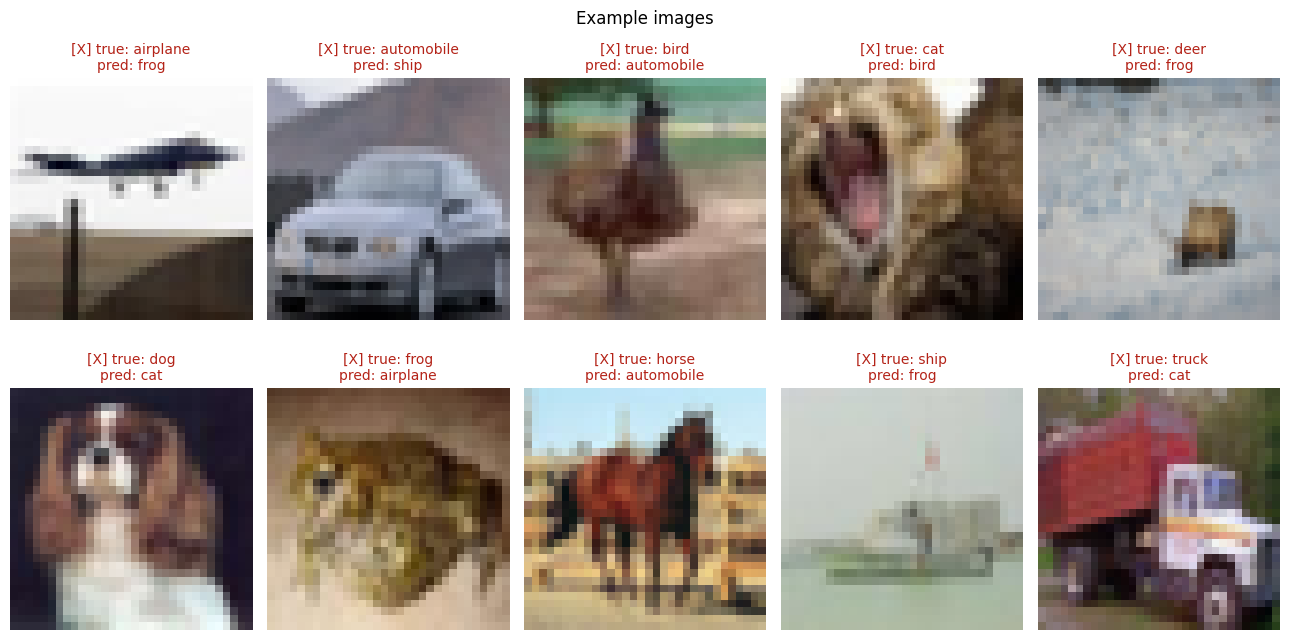

In [47]:
fig, axes = plt.subplots(2, 5, figsize=(13, 6.8))
for ax, idx, t, p in zip(axes.ravel(), example_idx, y_ex, pred_ex):
    ax.imshow(X_img[idx])
    mark = 'O' if t == p else 'X'
    ax.set_title(f'[{mark}] true: {CLASSES[t]}\npred: {CLASSES[p]}', fontsize=10,
                 color='#1a7f37' if t == p else '#b42318')
    ax.axis('off')
fig.suptitle('Example images', fontsize=12)
plt.tight_layout(h_pad=2.5); plt.show()

## 4. 다중 클래스 SVM hinge loss

이미지 $i$의 점수 벡터를 $s = f(x_i; W, b)$, 정답 클래스를 $y_i$라 할 때

$$L_i = \sum_{j \neq y_i} \max(0,\; s_j - s_{y_i} + \Delta), \qquad \Delta = 1$$

전체 손실은 선택한 이미지들의 평균 $L = \frac{1}{N}\sum_i L_i$. (학습을 하지 않으므로 정규화 항은 X)

In [48]:
def svm_loss(scores, y, delta=1.0):
    N = scores.shape[1]
    correct = scores[y, np.arange(N)]
    margins = np.maximum(0, scores - correct + delta)
    margins[y, np.arange(N)] = 0
    return margins.sum(axis=0)

svm_per_image = svm_loss(scores, y_ex)

svm_df = pd.DataFrame({'정답': [CLASSES[t] for t in y_ex],
                       '정답 점수': scores[y_ex, np.arange(len(y_ex))],
                       'SVM loss L_i': svm_per_image}, index=score_df.index)
print(svm_df.to_string())
print(f'\n평균 SVM loss = {svm_per_image.mean():.4f}')

                            정답   정답 점수  SVM loss L_i
#257 (airplane)       airplane -0.5145       13.9893
#5422 (automobile)  automobile -0.3282       12.2149
#9603 (bird)              bird  0.0229        8.4445
#53 (cat)                  cat  0.1693        7.4559
#8153 (deer)              deer  0.0042        9.5258
#9939 (dog)                dog -0.0345        9.1126
#4243 (frog)              frog -0.1980       11.6159
#4154 (horse)            horse -0.1091        9.9449
#9932 (ship)              ship  0.3009        6.6666
#6274 (truck)            truck -0.0434        9.0270

평균 SVM loss = 9.7997


평균 손실이 약 9.8. 가중치가 작으면 모든 점수가 거의 0에 가까움 + 정답이 아닌 9개 클래스마다 $\max(0, 0 + 1) \approx 1$이 더해지기 때문.

즉 초기 SVM 손실 ≈ (클래스 수 − 1) = 9는 구현이 맞는지 확인하는 기준값. 실제 점수는 0이 아니라 조금씩 흩어져 있어서, 정답 점수가 낮은 이미지는 손실이 9보다 크고(#257: 13.99), 높은 이미지는 9보다 작음(#9932: 6.67). 이번 10장은 정답 점수가 우연히 평균적으로 조금 낮아서 평균이 9.80으로 9보다 약간 크게 나옴.

## 5. Softmax

$$P(Y = k \mid x_i) = \frac{e^{s_k}}{\sum_j e^{s_j}}$$


In [49]:
def softmax(scores):
    shifted = scores - scores.max(axis=0, keepdims=True)
    exp_s = np.exp(shifted)
    return exp_s / exp_s.sum(axis=0, keepdims=True)

probs = softmax(scores)
prob_df = pd.DataFrame(probs.T, columns=CLASSES, index=score_df.index)
prob_df['sum'] = probs.sum(axis=0)
prob_df

,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck,sum
#257 (airplane),0.0578,0.0721,0.0787,0.0822,0.1098,0.1197,0.1866,0.1077,0.1016,0.0839,1.0000
#5422 (automobile),0.0777,0.0717,0.0996,0.1082,0.1006,0.1139,0.1099,0.0972,0.1217,0.0995,1.0000
#9603 (bird),0.1149,0.1249,0.1050,0.0949,0.0972,0.0879,0.0983,0.0863,0.0868,0.1039,1.0000
#53 (cat),0.0896,0.0964,0.1223,0.1161,0.0961,0.0931,0.0996,0.0967,0.1030,0.0872,1.0000
#8153 (deer),0.0795,0.0918,0.0882,0.0769,0.0936,0.1229,0.1287,0.1066,0.1142,0.0976,1.0000
#9939 (dog),0.1140,0.0807,0.0919,0.1319,0.1073,0.0976,0.0775,0.1150,0.0864,0.0977,1.0000
#4243 (frog),0.1218,0.1140,0.0870,0.0971,0.1068,0.0908,0.0764,0.1002,0.0988,0.1073,1.0000
#4154 (horse),0.1103,0.1293,0.1037,0.0781,0.1190,0.0846,0.0955,0.0899,0.1034,0.0861,1.0000
#9932 (ship),0.0793,0.0924,0.0872,0.0736,0.0963,0.1201,0.1339,0.1085,0.1239,0.0847,1.0000
#6274 (truck),0.0914,0.1038,0.1152,0.1213,0.0912,0.0865,0.0831,0.1064,0.1021,0.0991,1.0000


이미지 #257 (정답: airplane, 예측: frog)
              점수 s  exp(s)   확률 P
airplane   -0.5145  0.5978 0.0578
automobile -0.2927  0.7462 0.0721
bird       -0.2054  0.8143 0.0787
cat        -0.1615  0.8508 0.0822
deer        0.1277  1.1362 0.1098
dog         0.2145  1.2392 0.1197
frog        0.6585  1.9318 0.1866
horse       0.1085  1.1146 0.1077
ship        0.0504  1.0517 0.1016
truck      -0.1412  0.8683 0.0839

점수 범위: -0.5145 ~ 0.6585
확률 범위: 0.0578 ~ 0.1866  (균등 확률 = 0.1)


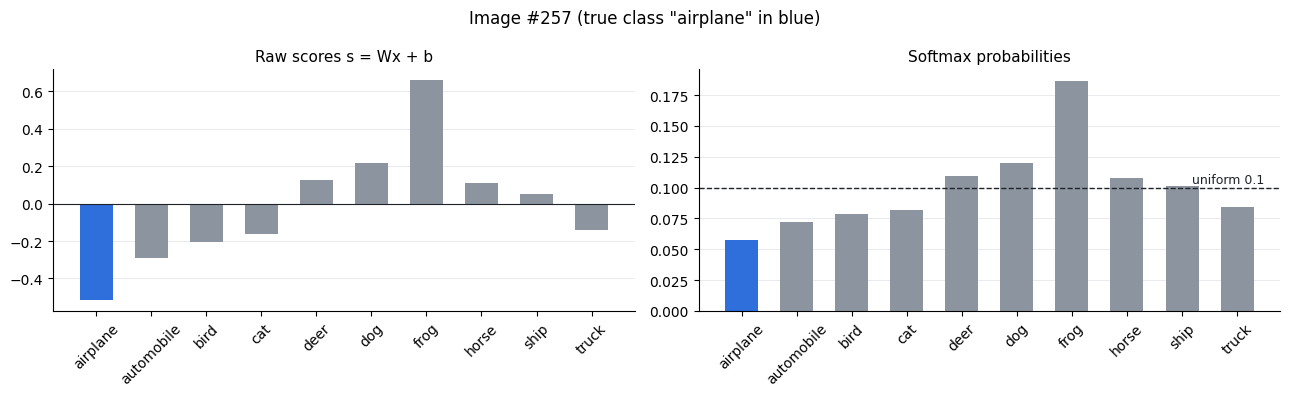

In [50]:
k = 0   # 첫 번째 이미지 예시
idx = example_idx[k]
cmp_df = pd.DataFrame({'점수 s': scores[:, k], 'exp(s)': np.exp(scores[:, k]),
                       '확률 P': probs[:, k]}, index=CLASSES)
print(f'이미지 #{idx} (정답: {CLASSES[y_ex[k]]}, 예측: {CLASSES[pred_ex[k]]})')
print(cmp_df.to_string())
print(f'\n점수 범위: {scores[:, k].min():.4f} ~ {scores[:, k].max():.4f}')
print(f'확률 범위: {probs[:, k].min():.4f} ~ {probs[:, k].max():.4f}  (균등 확률 = 0.1)')

INK, MUTED, ACCENT = '#1f2328', '#8c959f', '#2f6fdb'
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
bar_colors = [ACCENT if i == y_ex[k] else MUTED for i in range(K)]
ax1.bar(CLASSES, scores[:, k], color=bar_colors, width=0.6)
ax1.axhline(0, color=INK, lw=0.8)
ax1.set_title('Raw scores s = Wx + b', fontsize=11)
ax2.bar(CLASSES, probs[:, k], color=bar_colors, width=0.6)
ax2.axhline(0.1, color=INK, lw=1, ls='--')
ax2.text(K - 0.5, 0.101, 'uniform 0.1', ha='right', va='bottom', fontsize=9, color=INK)
ax2.set_title('Softmax probabilities', fontsize=11)
for ax in (ax1, ax2):
    ax.tick_params(axis='x', rotation=45)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='#e5e7eb', lw=0.6); ax.set_axisbelow(True)
fig.suptitle(f'Image #{idx} (true class "{CLASSES[y_ex[k]]}" in blue)', fontsize=12)
plt.tight_layout(); plt.show()

## 6. 올바르게 분류한 사례와 잘못 분류한 사례

In [51]:
correct_mask = pred_ex == y_ex
print(f'예시 10장 중 맞힌 이미지: {correct_mask.sum()}장')

all_scores = linear_classifier(X, W, b)
all_pred = all_scores.argmax(axis=0)
print(f'전체 10,000장 중 우연히 맞힌 비율: {(all_pred == y).mean():.3f} (무작위 추측 기대값 0.1)')
print('클래스별 예측 횟수:', {c: int(n) for c, n in zip(CLASSES, np.bincount(all_pred, minlength=K))})

예시 10장 중 맞힌 이미지: 0장
전체 10,000장 중 우연히 맞힌 비율: 0.085 (무작위 추측 기대값 0.1)
클래스별 예측 횟수: {'airplane': 1010, 'automobile': 1058, 'bird': 811, 'cat': 2206, 'deer': 455, 'dog': 694, 'frog': 1781, 'horse': 606, 'ship': 737, 'truck': 642}


예시 10장에는 맞힌 사례가 없어서, 전체 데이터에서 올바르게 분류된 이미지 2장을 시드 기반으로 무작위 선택해 잘못 분류된 예시 2장과 함께 비교

In [52]:
correct_pool = np.where(all_pred == y)[0]
wrong_pool = np.where(all_pred != y)[0]
case_idx = np.concatenate([rng.choice(correct_pool, 2, replace=False),
                           example_idx[~correct_mask][:2]])
case_names = ['올바른 분류', '올바른 분류', '잘못된 분류', '잘못된 분류']

case_scores = linear_classifier(X[:, case_idx], W, b)
case_probs = softmax(case_scores)
case_y = y[case_idx]
case_pred = case_scores.argmax(axis=0)
case_svm = svm_loss(case_scores, case_y)

rows = []
for k, (idx, name) in enumerate(zip(case_idx, case_names)):
    srt = case_probs[:, k].argsort()[::-1]
    rows.append({'구분': name, '이미지': f'#{idx}', '정답': CLASSES[case_y[k]], '예측': CLASSES[case_pred[k]],
                 '정답 점수': case_scores[case_y[k], k], '정답 확률': case_probs[case_y[k], k],
                 '1-2위 확률 차': case_probs[srt[0], k] - case_probs[srt[1], k],
                 'SVM loss': case_svm[k]})
case_df = pd.DataFrame(rows).set_index('이미지')
case_df

,구분,정답,예측,정답 점수,정답 확률,1-2위 확률 차,SVM loss
이미지,,,,,,,
#5402,올바른 분류,deer,deer,0.1445,0.1093,0.0017,8.0954
#2928,올바른 분류,automobile,automobile,0.1531,0.1104,0.0014,7.9416
#257,잘못된 분류,airplane,frog,-0.5145,0.0578,0.0669,13.9893
#5422,잘못된 분류,automobile,ship,-0.3282,0.0717,0.0078,12.2149


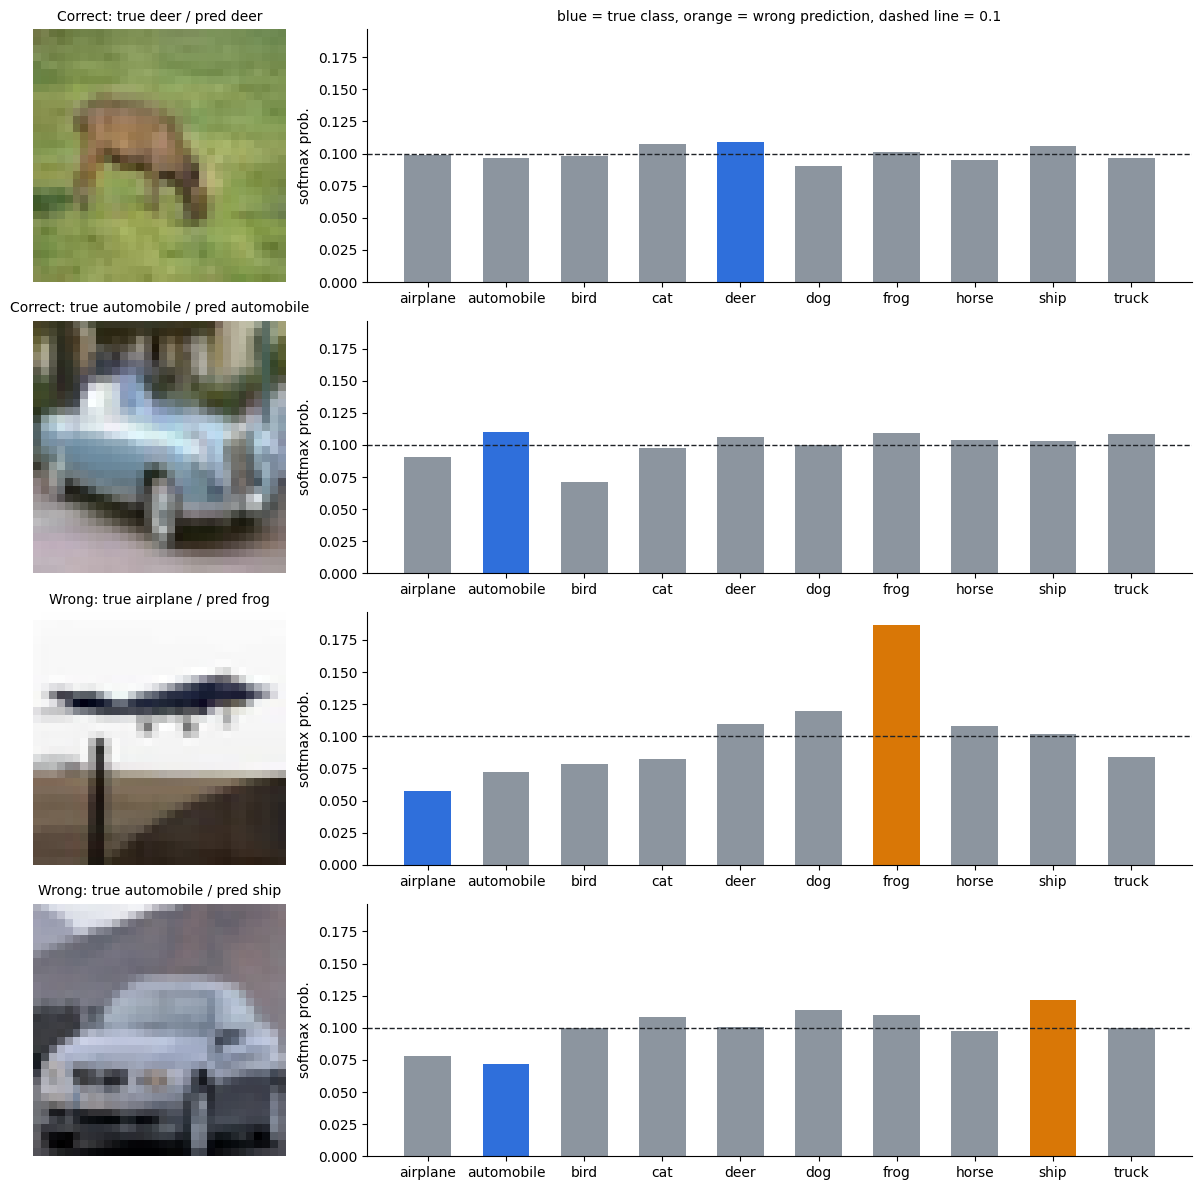

In [53]:
fig, axes = plt.subplots(4, 2, figsize=(12, 12), gridspec_kw={'width_ratios': [1, 3]})
ymax = case_probs.max() + 0.01
for k, (idx, name) in enumerate(zip(case_idx, ['Correct', 'Correct', 'Wrong', 'Wrong'])):
    t, p = case_y[k], case_pred[k]
    axes[k, 0].imshow(X_img[idx]); axes[k, 0].axis('off')
    axes[k, 0].set_title(f'{name}: true {CLASSES[t]} / pred {CLASSES[p]}', fontsize=10)
    cols_ = [ACCENT if i == t else ('#d97706' if i == p else MUTED) for i in range(K)]
    axes[k, 1].bar(CLASSES, case_probs[:, k], color=cols_, width=0.6)
    axes[k, 1].axhline(0.1, color=INK, lw=1, ls='--')
    axes[k, 1].set_ylim(0, ymax); axes[k, 1].set_ylabel('softmax prob.')
    axes[k, 1].spines[['top', 'right']].set_visible(False)
axes[0, 1].set_title('blue = true class, orange = wrong prediction, dashed line = 0.1', fontsize=10)
plt.tight_layout(); plt.show()

결과 해석

- **올바른 분류(#5402 deer, #2928 automobile)**: 정답 확률이 각각 0.109, 0.110으로 균등 확률 0.1보다 아주 조금 높을 뿐이고, 2위 클래스와의 확률 차도 0.002 이하. 모델이 사슴이나 자동차를 알아본 것이 아니라, 무작위 `W`가 우연히 정답 클래스에 근소하게 가장 큰 점수를 준 것.
- **잘못된 분류(#257 airplane→frog, #5422 automobile→ship)**: 예측 클래스의 확률도 0.12~0.19 수준이라, 확신을 갖고 틀렸다기보다 거의 고르게 퍼진 확률 중 하나가 조금 더 높았을 뿐.
- 예시 10장은 모두 틀렸고, 전체 10,000장에서 맞힌 비율도 8.5%로 무작위 추측(10%)과 비슷한 수준. 또 예측이 cat(2,206회)·frog(1,781회)에 쏠리고 deer는 455회에 그치는데, 이는 무작위 `W`의 일부 행이 평균적인 이미지 방향과 우연히 더 잘 맞기 때문.

## 7. 클래스별 가중치 벡터 시각화

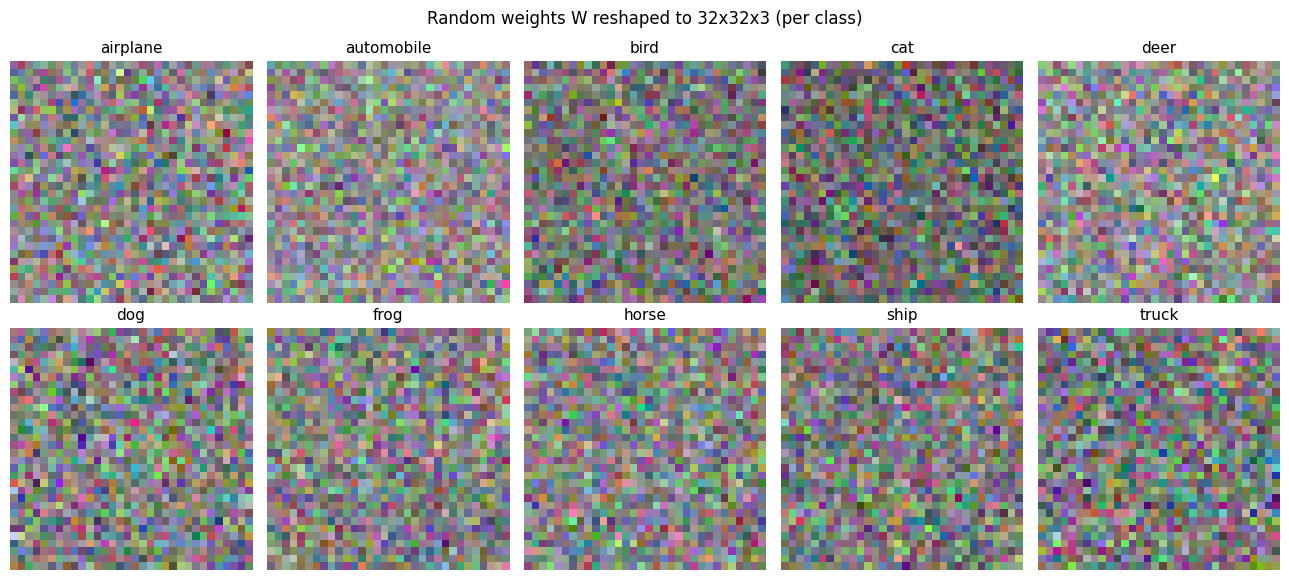

In [55]:
fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for c, ax in enumerate(axes.ravel()):
    w_img = W[c].reshape(32, 32, 3)
    w_img = (w_img - w_img.min()) / (w_img.max() - w_img.min())   # 0~1로 정규화해서 표시
    ax.imshow(w_img, interpolation='nearest')
    ax.set_title(CLASSES[c], fontsize=11); ax.axis('off')
fig.suptitle('Random weights W reshaped to 32x32x3 (per class)', fontsize=12)
plt.tight_layout(); plt.show()

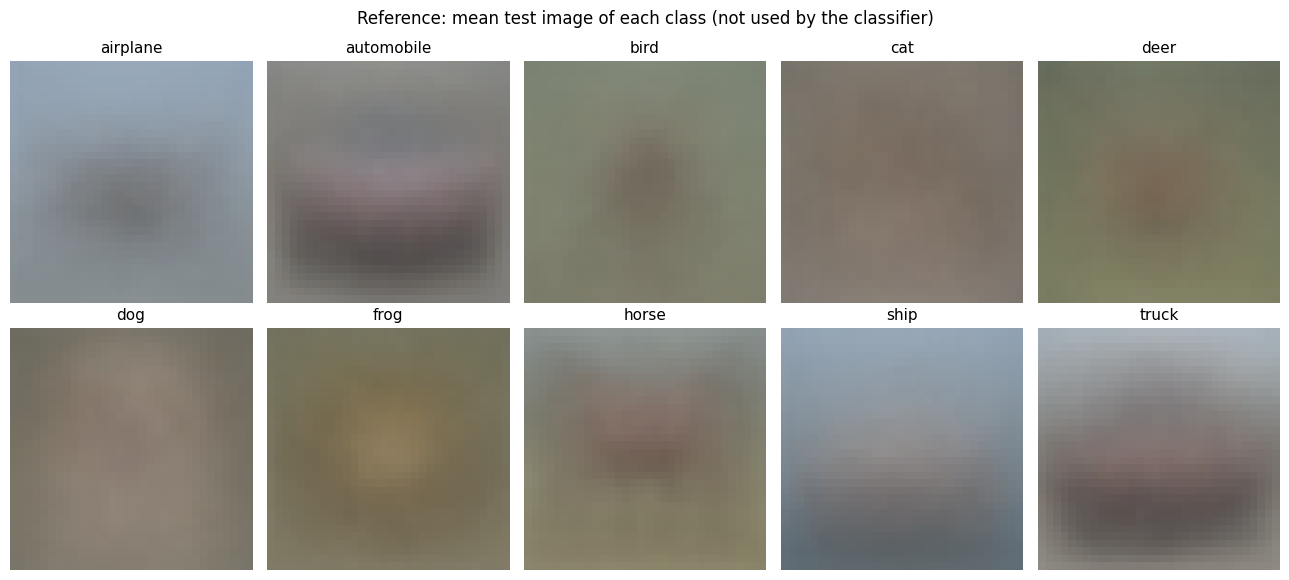

서로 다른 클래스 가중치 벡터 간 상관계수: 평균 -0.0026, 최대 절댓값 0.0521


In [56]:
fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(X_flat[y == c].mean(axis=0).reshape(32, 32, 3))
    ax.set_title(CLASSES[c], fontsize=11); ax.axis('off')
fig.suptitle('Reference: mean test image of each class (not used by the classifier)', fontsize=12)
plt.tight_layout(); plt.show()

corr = np.corrcoef(W)
off_diag = corr[~np.eye(K, dtype=bool)]
print(f'서로 다른 클래스 가중치 벡터 간 상관계수: 평균 {off_diag.mean():.4f}, 최대 절댓값 {np.abs(off_diag).max():.4f}')

무작위 가중치에서 클래스별 특징이 나타나지 않는 이유

- `W`의 3072×10개 값이 모두 같은 정규분포에서 서로 독립적으로 뽑힘. -> 그래서 각 행을 이미지로 바꾸면 인접 픽셀끼리 아무 관계가 없는 컬러 노이즈가 됨. 실제 이미지처럼 덩어리진 형태나 색 영역이 생길 수 없는 것.
- 가중치를 정하는 과정에서 데이터를 한 번도 보지 않음 -> 학습은 손실의 기울기를 따라 `W`를 고치는 과정인데, 이를 하지 않았으니 `W`에 이미지 정보가 전혀 들어 있지 않음.
- 그래서 airplane 행과 truck 행 사이에 구조적인 차이가 없음. 클래스 이름만 다를 뿐 모두 같은 분포의 노이즈이고, 행 간 상관계수도 거의 0.
- 학습을 하면 위의 클래스 평균 이미지처럼 하늘·바다가 많은 airplane·ship 행은 파란 배경, frog·deer 행은 녹색·갈색 배경을 띠는 등 클래스별 템플릿이 나타남.